# C06 — 35번 캐리어 오프닝 앞쪽 슬라이드 교체 (2026-11-12, M-05-02-2)

정리본: [`cases/C06.md`](cases/C06.md). 새 일지(11-09 ~ 11-16)로 들어온 사건이다.

| 단계 | 내용 |
|---|---|
| 1 | 일지 |
| 2 | 11-12 아침 2라인 — 와이어 스위치 정지 때 35번이 오프닝 위치 |
| 3 | 35번 재감지 — P00451에서 11-10 07시 시작, 교체 뒤 0 |
| 4 | 6개 센서 하루 칸 — P00451만 움직임 |
| 5 | 엣지 경고 W0274 — 11-10 12:47부터 35번 포함 |
| 6 | 모델 실시간 칸 (DB 재생) |

In [1]:
import sys, json; sys.path.insert(0, "..")
from contextlib import redirect_stdout
from io import StringIO
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from review_lib import paths, db, backend, plot
pd.set_option("display.width", 250); pd.set_option("display.max_rows", 200); pd.set_option("display.max_columns", 40)
FIGS = paths.CHECK_DIRS["conveyor"] / "figs"; RC = paths.CACHE_DIR / "replay"
MD_TAGS = ["P00450", "P00451", "P00458", "P00459", "D05200", "D05210", "D05299", "M00042", "M00045",
           "M00601", "M00611", "AL_Line_Word", "MD_FWD_Zone_In_PS_CHK_Err", "Now_Actual_Wagon_Num",
           "R00055", "R00060", "Hz_In_Conv", "Conv_Run_Out", "Auto_Running_PL"]
md_day = lambda d: db.fetch_day(d, MD_TAGS, group="md_num")
WAGON = 35
ACT = (pd.Timestamp("2026-11-12 06:50"), pd.Timestamp("2026-11-12 07:03"))


def md_passes(raw, counter="R00055", first="P00450"):
    """C03 노트북과 같은 함수 — 진입 센서 통과마다 PLC 기준 대차 번호와 2.5초 안 재감지."""
    r = raw[counter].ffill().to_numpy(float); t = raw.index.to_numpy()
    dr = np.diff(r, prepend=r[0])
    prim = np.flatnonzero(dr < -50); sec = np.flatnonzero((dr <= -2) & (dr >= -50))
    anchor = set()
    for i in np.flatnonzero(raw[first].fillna(0).to_numpy() > 0):
        c = prim[(t[prim] <= t[i]) & (t[prim] >= t[i] - np.timedelta64(3, "s"))]
        if len(c): anchor.add(c[-1])
    wag, cur = [], None
    for i in prim:
        cur = 1 if i in anchor else (None if cur is None else cur % 42 + 1); wag.append(cur)
    k = np.searchsorted(sec, prim, side="right"); ok = k < len(sec)
    j = sec[np.minimum(k, len(sec) - 1)] if len(sec) else np.zeros(len(prim), int)
    g = (t[j] - t[prim]) / np.timedelta64(1, "s")
    return pd.DataFrame({"t": t[prim], "wagon": pd.array(wag, dtype="Int64"), "gap_s": np.where(ok & (g <= 2.5), g, np.nan),
                         "early": -dr[prim] + r[prim] - 1}).assign(rearm=lambda d: d.gap_s.notna())

## 1. 일지

In [2]:
acts = pd.read_csv(paths.ACTIONS_DIR / "actions_conveyor.csv")
acts[acts.incident_id == "C06"][["작업ID", "journal", "start_dt", "end_dt", "라인번호", "설비상세", "조치", "담당", "출처"]].T

,7
작업ID,M-05-02-2
journal,기계실
start_dt,2026-11-12 06:50:00
end_dt,2026-11-12 07:03:00
라인번호,2
설비상세,35번 캐리어 오프닝 앞쪽 슬라이드
조치,캐리어 하차 및 슬라이드 교체
담당,공무
출처,261109-261116 기계실업무일지.pdf p.2 NO.2


## 2. 11-12 아침 2라인

`Conv_Run_Out` 운전·정지와 알람 워드. 대차 번호는 `Now_Actual_Wagon_Num`(P00140 기준)에서 센서마다 고정 차이를 뺀다
(오프닝 P00164 −26, 후진 P00459 −41 — `core_params.n_fix`).

In [3]:
r12 = md_day("2026-11-12").loc["2026-11-12 06:20":"2026-11-12 07:10"]
w = r12[["Conv_Run_Out", "AL_Line_Word", "Hz_In_Conv", "R00060", "Now_Actual_Wagon_Num"]].copy()
w["오프닝 대차(=Now−26)"] = (w.Now_Actual_Wagon_Num - 26 - 1) % 42 + 1
w[(w[["Conv_Run_Out", "AL_Line_Word"]].diff().abs().sum(axis=1) > 0)]

,Conv_Run_Out,AL_Line_Word,Hz_In_Conv,R00060,Now_Actual_Wagon_Num,오프닝 대차(=Now−26)
Time,,,,,,
2026-11-12 06:23:25.623420,1.0,0.0,405.0,77.0,30.0,4.0
2026-11-12 06:30:23.667952,0.0,55.0,324.0,12.0,19.0,35.0
2026-11-12 06:32:29.604991,0.0,0.0,324.0,12.0,19.0,35.0
2026-11-12 06:42:29.791043,0.0,60.0,150.0,12.0,19.0,35.0
2026-11-12 06:42:42.816456,0.0,0.0,150.0,12.0,19.0,35.0
2026-11-12 06:43:08.025114,1.0,0.0,150.0,12.0,19.0,35.0
2026-11-12 06:43:10.069785,0.0,0.0,150.0,10.0,19.0,35.0
2026-11-12 06:43:17.280619,1.0,0.0,150.0,10.0,19.0,35.0
2026-11-12 06:43:20.350153,0.0,0.0,150.0,5.0,19.0,35.0


- **06:30:23 알람 55 "CONVEYOR LINE WIRE S/W"**(비상 당김줄)로 라인이 섰다. 그때 오프닝 위치(P00164)의 대차가 **35번**이다.
- 06:42 알람 60(체인지존 인터록), 06:43 저속(15 Hz) **역방향** 인칭 — 후진 Unit 카운터 R00060이 12 → 0으로 내려가 알람 29(MD_REV_Zone_In_PS_CHK_Err)가 났다.
  알람 29는 R00060이 160을 넘거나(P00459가 대차를 놓침) 0일 때 걸린다(`Preparation.il` 768~777, 875~877). 여기서는 역방향 운전 탓이다.
- 06:50 ~ 06:56 다시 돌렸다가 06:56 ~ 07:04 정지. 일지의 하차·슬라이드 교체(06:50 ~ 07:03)다.

## 3. 35번 재감지 — P00451에서 11-10 07시 시작, 교체 뒤 0

C03에서 쓴 카운터 방법(R00055·R00060 리셋)으로 PLC 기준 35번 통과의 재감지를 센다.

In [4]:
rows, hr = [], []
for d in pd.date_range("2026-10-26", "2026-11-14"):
    raw = md_day(d)
    if len(raw) < 20000: continue
    for s, c, f in [("P00451 전진 진입", "R00055", "P00450"), ("P00459 후진 진입", "R00060", "P00458")]:
        p = md_passes(raw, c, f); w = p[p.wagon == WAGON]
        rows.append((f"{d:%m-%d}", s, round(w.rearm.mean(), 2)))
        if s.startswith("P00451") and d >= pd.Timestamp("2026-11-09") and d <= pd.Timestamp("2026-11-12"):
            hr.append(w.assign(t=pd.to_datetime(w.t)))
pd.DataFrame(rows, columns=["day", "sensor", "rearm"]).pivot(index="sensor", columns="day", values="rearm")

day,10-26,10-27,10-28,10-29,10-30,10-31,11-02,11-03,11-04,11-05,11-06,11-09,11-10,11-11,11-12,11-13,11-14
sensor,,,,,,,,,,,,,,,,,
P00451 전진 진입,0.99,1.0,0.99,0.97,1.0,0.57,0.0,0.0,0.0,0.0,0.0,0.0,0.61,0.3,0.0,0.0,0.0
P00459 후진 진입,0.00,0.0,0.00,0.00,0.0,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.00,0.0,0.0,0.0,0.0


In [5]:
H35 = pd.concat(hr)
H35.groupby(H35.t.dt.strftime("%m-%d %H")).agg(통과=("t", "size"), 재감지=("rearm", "sum"),
                                              앞펄스_간격_초=("gap_s", "median"), 리셋직전카운터=("early", "median"))

,통과,재감지,앞펄스_간격_초,리셋직전카운터
t,,,,
11-09 05,2,0,NaN,137.0
11-09 06,6,0,NaN,137.0
11-09 07,6,0,NaN,137.0
11-09 08,5,0,NaN,136.0
11-09 09,7,0,NaN,135.0
11-09 10,6,0,NaN,137.0
11-09 11,4,0,NaN,136.5
11-09 12,6,0,NaN,137.5
11-09 13,6,0,NaN,137.5


- 35번은 10-31 센서 조정 전까지 P00451에서 상시 재감지(표식 13카운트 앞)였고, 조정 뒤(11-02 ~ 11-09)는 0이었다.
- **11-10 07시에 다시 생겼다.** 시간마다 2 ~ 6번, 본 감지 약 1.5초 앞(카운터 123 ~ 126에서 리셋)에서 먼저 켜진다. 조정 전과 다른 자리다.
- 11-11에도 이어지다가(시간마다 1 ~ 5번) **11-12 06:56 하차·교체 뒤로 0**이다.
- 후진 진입(P00459)에서는 35번 재감지가 없다.

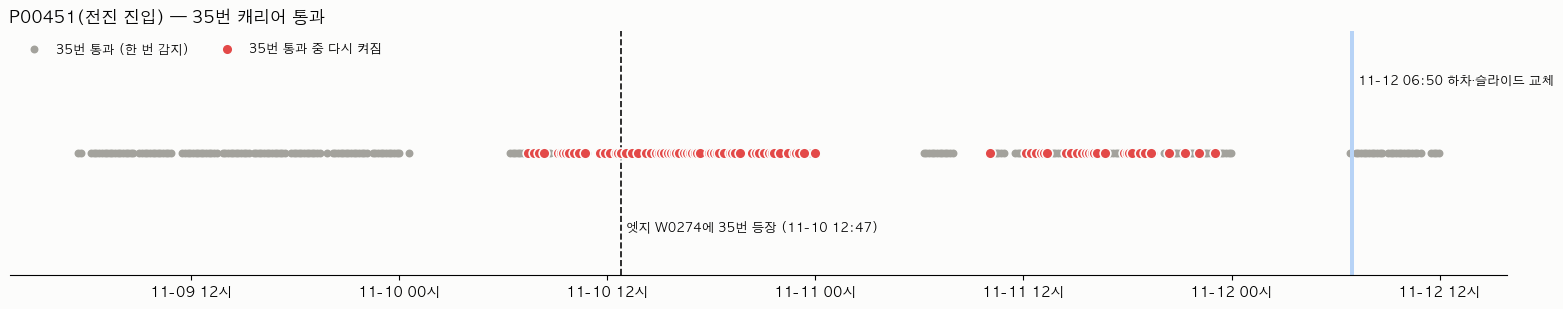

In [6]:
d = H35[(H35.t >= "2026-11-09 05:00") & (H35.t < "2026-11-12 12:00")]
fig, ax = plt.subplots(figsize=(16, 3.2), facecolor="#fcfcfb"); ax.set_facecolor("#fcfcfb")
ax.scatter(d[~d.rearm].t, np.zeros((~d.rearm).sum()), s=22, color="#a3a29c", label="35번 통과 (한 번 감지)")
ax.scatter(d[d.rearm].t, np.zeros(d.rearm.sum()), s=60, color="#e34948", ec="#fcfcfb", lw=1.2, label="35번 통과 중 다시 켜짐", zorder=3)
ax.axvspan(*ACT, color="#b7d3f6", lw=0); ax.text(ACT[1], 0.6, " 11-12 06:50 하차·슬라이드 교체", fontsize=9, va="center")
ax.axvline(pd.Timestamp("2026-11-10 12:47:34"), color="#0b0b0b", lw=1.2, ls="--")
ax.text(pd.Timestamp("2026-11-10 12:50"), -0.6, " 엣지 W0274에 35번 등장 (11-10 12:47)", fontsize=9, va="center")
ax.set_yticks([]); ax.set_ylim(-1, 1)
for s in ["top", "right", "left"]: ax.spines[s].set_visible(False)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d %H시"))
ax.legend(loc="upper left", frameon=False, fontsize=9, ncol=2)
ax.set_title("P00451(전진 진입) — 35번 캐리어 통과", loc="left", fontsize=12)
fig.tight_layout(); fig.savefig(FIGS / "C06_wagon35_rearm.png", dpi=110, facecolor="#fcfcfb")

## 4. 6개 센서 하루 칸 (대차 35)

엣지 가동일 기록(~11-05) + DB 재생 하루 칸(11-06 ~ 11-14).

In [7]:
backend.use("v2.2")
with redirect_stdout(StringIO()):
    from tools_yeji.conveyor_models.core_judge import judge
H = pd.DataFrame(json.load(open(paths.MODEL_VERSIONS["v2.2"]["backend"] / "data" / "conveyor_core_history.json")))
for f in ["fp_late_1105_1111", "wk3_1111_1115"]:
    x = pd.DataFrame(pd.read_pickle(RC / f"{f}.pkl")["history"]); H = pd.concat([H, x[x.day > H.day.max()]])
H["day"] = pd.to_datetime(H.day); J = judge(H)
j = J[(J.wagon == WAGON) & (J.day >= "2026-10-28")]
pd.concat({c: j.pivot_table(index="sensor", columns=j.day.dt.strftime("%m-%d"), values=c, aggfunc="first") for c in ["state", "rearm", "rise_off", "width_ex"]}, axis=1).round(2)

state                                                                                         rearm                                ... rise_off                               width_ex                                                        \
day      10-28   10-29   10-30   10-31 11-02 11-03 11-04 11-05 11-06 11-09   11-10   11-11 11-12 11-13 10-28 10-29 10-30 10-31 11-02 11-03  ...    11-06 11-09 11-10 11-11 11-12 11-13    10-28 10-29 10-30 10-31 11-02 11-03 11-04 11-05 11-06 11-09   
sensor                                                                                                                                      ...                                                                                                         
P00140      정상      정상      정상      정상    정상    정상    정상    정상    정상    정상      정상      정상    정상    정상  0.00  0.00  0.00  0.00   0.0   0.0  ...      0.0   0.0   0.0   0.0   0.0   0.0     0.00   0.0 -0.50  -1.0  0.00 -1.00   0.0  1.00  1.00   0.0   
P00141      정상      정상      정상      정상    정상    정상    정상    정상    정상    정상      정상      정상    정상    정상  0.00  0.00  0.00  0.00   0.0   0.0  ...      0.0   0.0   0.0   0.0  -1.0  -1.0     1.00   1.0 -1.00  -1.0 -1.00 -1.00   0.0  1.00  0.00   1.0   
P00154      정상      정상      정상      정상    정상    정상    정상    정상    정상    정상      정상      정상    정상    정상  0.00  0.00  0.00  0.00   0.0   0.0  ...      1.0   0.0   0.0   0.0   0.0   0.0    -2.00  -2.0 -1.75   0.0 -1.75 -1.00  -2.0 -1.75 -1.00  -1.0   
P00164      정상      정상      정상      정상    정상    정상    정상    정상    정상    정상      정상      정상    정상    정상  0.00  0.00  0.00  0.00   0.0   0.0  ...      1.0   1.0   1.0   1.0   1.0   0.0    -1.00  -1.0 -1.00  -1.0 -2.00 -2.00  -2.0 -1.00 -1.00  -1.5   
P00451  이물(분리)  이물(분리)  이물(분리)  이물(분리)    정상    정상    정상    정상    정상    정상  이물(분리)  이물(분리)    정상    정상  0.99  1.09  1.57  0.77   0.0   0.0  ...      0.0   0.0 -10.0   0.0   0.0   0.0     0.00   0.0 -1.00  -1.0 -2.00 -1.75  -2.0 -1.50 -0.25   0.0   
P00459      정상      정상      정상      정상    정상    정상    정상    정상    정상    정상      정상      정상    정상    정상  0.00  0.00  0.00  0.00   0.0   0.0  ...      1.0   1.0   1.0   1.0   0.0   0.0    -0.25   0.0  0.00   0.5  0.00 -1.00   0.0 -0.50  0.50   0.0   

                                
day    11-10 11-11 11-12 11-13  
sensor                          
P00140   0.0  0.00  -0.5  -1.0  
P00141   0.0  0.50   0.0   0.0  
P00154   0.0 -1.00   0.0   0.0  
P00164  -2.0  0.00  -1.0  -1.0  
P00451   0.0 -0.75  -1.0  -2.0  
P00459   0.0  0.00   0.0   0.0  

[6 rows x 56 columns]

## 5. 엣지 경고 — W0274에 35번이 들어온 때

경고 로그는 11-11 08:50까지만 있다(그 뒤 로그는 아직 받지 못했다).

In [8]:
ev = pd.read_csv(paths.EPISODES_DIR / "warning_events.csv", low_memory=False, parse_dates=["ts"])
e = ev[(ev.kind == "conveyor") & ev.key.astype(str).str.startswith("P00451") & (ev.ts >= "2026-11-10")]
e = e.copy(); e["35번 포함"] = e.wagon_nos.fillna("").astype(str).str.split(";").apply(lambda L: str(WAGON) in L)
first = e[e["35번 포함"]].ts.min()
print("35번 처음 등장:", first, "→ 교체 시작까지", round((ACT[0] - first).total_seconds() / 3600, 1), "시간")
e[["ts", "event", "key", "active", "wagon_nos", "35번 포함"]]

35번 처음 등장: 2026-11-10 12:47:34.135000 → 교체 시작까지 42.0 시간


,ts,event,key,active,wagon_nos,35번 포함
10883,2026-11-10 06:00:42.400,updated,P00451:wagons,True,13;22,False
10887,2026-11-10 06:45:56.675,updated,P00451:wagons,True,10;13;22,False
10909,2026-11-10 07:22:08.435,updated,P00451:wagons,True,13;22,False
10910,2026-11-10 07:23:08.664,updated,P00451:wagons,True,22,False
10918,2026-11-10 07:31:11.844,updated,P00451:wagons,True,10;22,False
10926,2026-11-10 07:40:14.291,updated,P00451:wagons,True,22,False
10927,2026-11-10 07:41:14.511,updated,P00451:wagons,True,13;22,False
10933,2026-11-10 07:49:17.508,updated,P00451:wagons,True,10;13;22,False
10936,2026-11-10 07:58:20.786,updated,P00451:wagons,True,13;22,False
10949,2026-11-10 08:19:26.996,updated,P00451:wagons,True,13,False


- **W0274(P00451 `wagon_rearm`)에 35번이 11-10 12:47에 처음 들어왔다.** 문구는 "한 대차에서 다시 켜짐 → 표식 앞 떨어진 이물 또는 채터링"이다.
- 그 뒤 들어왔다 빠졌다 하면서 로그 끝(11-11 08:50)까지 이어진다. 15:05 ~ 22:10에는 센서 경고(W0318 센서 재감지)가 켜졌다 꺼졌다 해서, 켜진 동안은 대차 경고가 센서 경고에 묶였다.
- 같은 경고에 든 4·7·9·10·13·22번은 C03 조치 뒤 남은 재감지다(경고_검토 4절).

## 6. 모델 실시간 칸 — DB 재생

DB 재생(11-05 ~ 11-11 `fp_late`, 11-11 ~ 11-15 `wk3`)에서 15분마다 P00451 대차 35 판정.

In [9]:
E = pd.concat([pd.read_pickle(RC / f"{f}.pkl")["evals"] for f in ["fp_late_1105_1111", "wk3_1111_1115"]]); E["t"] = pd.to_datetime(E.t)
e35 = E[(E.sensor == "P00451") & (E.wagon == WAGON)]
fl = E[(E.sensor == "P00451") & E.wagon.isna()]
print("재생 판정에 35번:", e35.t.min(), "~", e35.t.max(), f"({len(e35)}번, 상태 {sorted(e35.state.unique())})")
e35.groupby(e35.t.dt.strftime("%m-%d")).agg(처음=("t", "min"), 마지막=("t", "max"), 횟수=("t", "size"))

재생 판정에 35번: 2026-11-10 09:10:43.545054 ~ 2026-11-11 21:07:46.839659 (93번, 상태 ['이물(분리)', '흔들림'])


,처음,마지막,횟수
t,,,
11-10,2026-11-10 09:10:43.545054,2026-11-10 23:46:49.687735,37
11-11,2026-11-11 00:01:49.899442,2026-11-11 21:07:46.839659,56


## 7. 결론

1. **35번 캐리어의 이상은 교체 약 2일 전(11-10 07시)부터 P00451 재감지로 데이터에 나타났다.** 교체 직후 사라졌다.
2. **모델은 11-10 12:47에 35번을 짚었다**(W0274 "표식 앞 이물 또는 채터링"). 교체(11-12 06:50)까지 42시간 앞이다.
   현장 조치는 "35번 캐리어 오프닝 **앞쪽** 슬라이드 교체"다. 대차와 위치(표식 앞쪽)가 맞는다 → `TP`(부위 일치).
3. 다만 경고는 C03 잔여 대차들(4·7·9·10·13·22)과 한 건으로 묶여 있었고, 센서 경고가 켜질 때마다 묶였다. 35번이 "새로 생긴" 대차라는 것이 화면에서 드러나지 않았다.
   새로 생긴 재감지 대차를 따로 올리는 것이 개선점이다(경고_검토의 C03 잔여와 대비).